In [12]:
import torch
import torch.nn as nn
from torchvision import models
from torch.utils.data import DataLoader
from datasets import load_from_disk
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score, roc_curve, precision_recall_curve)
from sklearn.calibration import calibration_curve
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
import sys
import json
import random

PROJECT_ROOT = Path().resolve().parent
SRC_PATH = PROJECT_ROOT / "src"
DATA_PROCESSED_PATH = SRC_PATH / "data" / "processed"
VALIDATION_DATASET = DATA_PROCESSED_PATH / "validation_cats_dogs"
MODELS_PATH = PROJECT_ROOT / "models"
BEST_MODEL_SAVED = MODELS_PATH / "resnet50_best.pt"
JSON_PATH = MODELS_PATH / "label_mapping.json"

with open(str(JSON_PATH), "r") as f:
    labels = json.load(f)

LABEL_MAPPING = labels["labels"]

sys.path.append(str(SRC_PATH))

from data.dataset import CatsDogsDataset
from data.transforms import get_val_transformation

## **Carga del modelo y dataset de validación**

In [2]:
val_dataset = load_from_disk(str(VALIDATION_DATASET))
val_dataset_pytorch = CatsDogsDataset(val_dataset, transform=get_val_transformation())
val_loader = DataLoader(val_dataset_pytorch, 
                        batch_size=128,
                        shuffle=False,
                        )

dev = "cuda" if torch.cuda.is_available() else "cpu"
model = models.resnet50(weights=None)
model.fc = nn.Linear(model.fc.in_features, len(LABEL_MAPPING))
model = model.to(dev)

checkpoint = torch.load(str(BEST_MODEL_SAVED), map_location=torch.device(dev))
model.load_state_dict(checkpoint["model_state"])

<All keys matched successfully>

##  **Función evaluadora**

In [3]:
def evaluate(loaded_model, dataloader, device):
    loaded_model.eval()

    all_preds = []
    all_probs = []
    all_targets = []

    with torch.no_grad():
        for x, y in dataloader:
            x = x.to(device)
            y = y.to(device)

            logits = model(x)
            probs = torch.softmax(logits, dim=1)[:, 1]

            preds = torch.argmax(logits, dim=1)

            all_preds.extend(preds.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())
            all_targets.extend(y.cpu().numpy())
    
    return all_targets, all_preds, all_probs

## **Classification report**

In [4]:
y_true, y_pred, y_prob = evaluate(model, val_loader, dev)

print(classification_report(y_true, y_pred, target_names=LABEL_MAPPING))

              precision    recall  f1-score   support

         cat       0.99      0.97      0.98      2348
         dog       0.98      0.99      0.98      2334

    accuracy                           0.98      4682
   macro avg       0.98      0.98      0.98      4682
weighted avg       0.98      0.98      0.98      4682



Tal como nos indica este reporte, podemos observar que las tres métricas que lo conforman se enccuentran relativamente balanceadas en las dos categorías que forman parte del dataset.
Es justo destacar que el modelo mantiene un performance óptima y no resulta necesario realizar ajustes. 

## **Matriz de confusión**

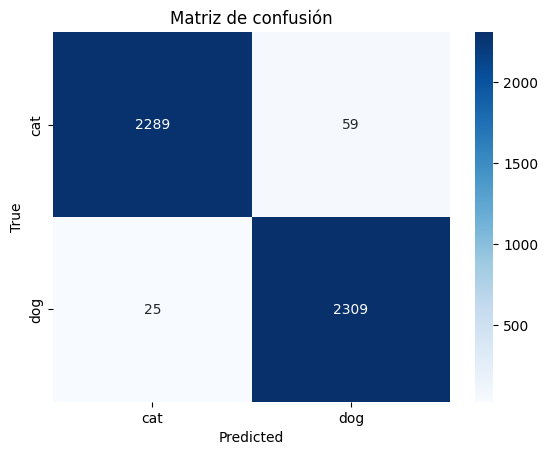

In [5]:
cm = confusion_matrix(y_true, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=LABEL_MAPPING, yticklabels=LABEL_MAPPING)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Matriz de confusión")
plt.show()

Aquí nuevamente podemos confirmar lo que hemos visto en el reporte anterior. La cantidad de casos verdaderos positivos y falsos positivos es relativamente similar, con una diferencia muy baja, lo que vuelve a indicar que el modelo es eficiente a la hora de realizar la clasificación. 

## **Curva ROC y AUC**

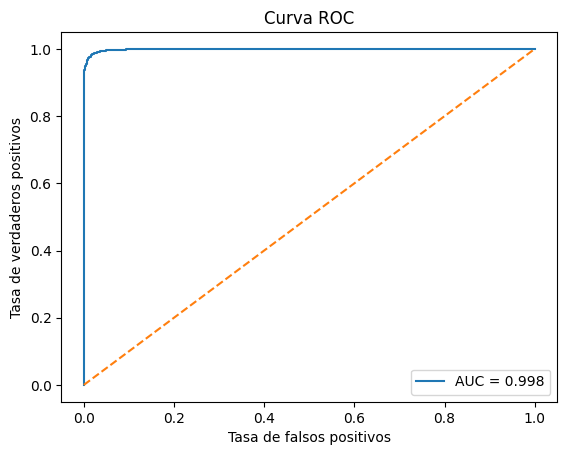

In [7]:
fpr, tpr, _ = roc_curve(y_true, y_prob)
roc_auc = roc_auc_score(y_true, y_prob)

plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
plt.plot([0,1], [0,1], "--")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.legend()
plt.title("Curva ROC")
plt.show()

A través de la curva ROC y el AUC, podemos distinguir que el modelo es eficiente a la hora de mantener una tasa alta de verdaderos positivos.

## **Curva Precision-Recall**

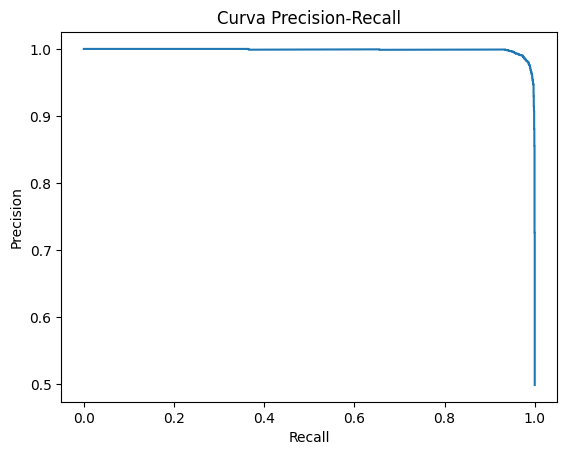

In [8]:
precision, recall, tresholds = precision_recall_curve(y_true, y_prob)

plt.plot(recall, precision)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Curva Precision-Recall")
plt.show()

## **Calibración**

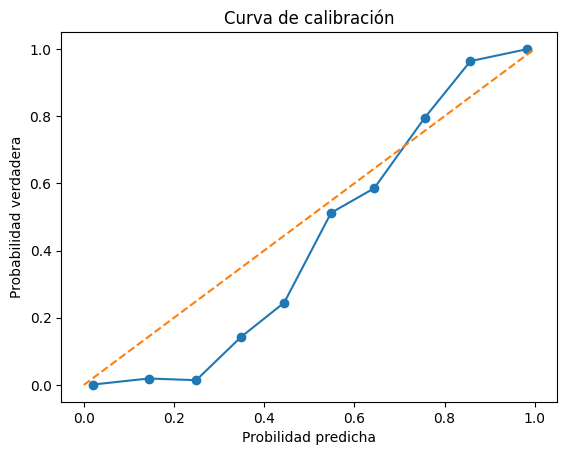

In [11]:
prob_true, prob_pred = calibration_curve(y_true, y_prob, n_bins=10)

plt.plot(prob_pred, prob_true, marker='o')
plt.plot([0,1], [0,1], "--")
plt.xlabel("Probilidad predicha")
plt.ylabel("Probabilidad verdadera")
plt.title("Curva de calibración")
plt.show()

En este aspecto si podemos ver que, con respecto a las probabilidades, el modelo es tendencioso a confiar cuando está muy seguro de que es la clasificación correcta.
Si observamos las probalidades altas, podremos ver que la calibración es correcta. En cuanto a las probabilidades medias y bajas, el modelo se encuentra mal calibrado ya que la curva está muy por debajo de la diagonal. 

## **Análisis de errores**

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.622571].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.1519828].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.8256302..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.0665298..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9306722..2.64].
Clipping input 

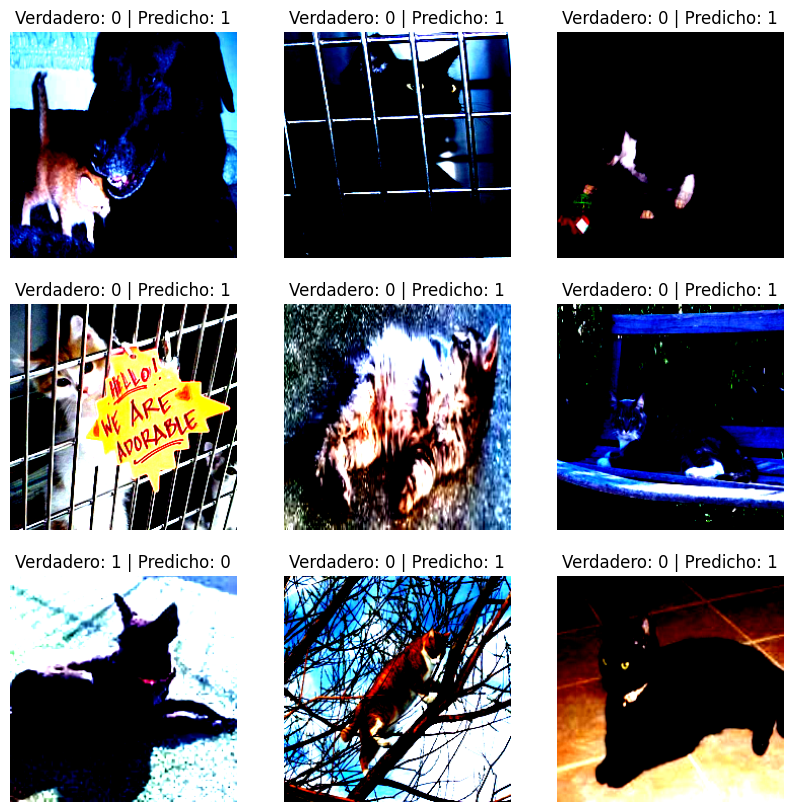

In [13]:
wrong_index = [i for i, (t, p) in enumerate(zip(y_true, y_pred)) if t != p]

sample_index = random.sample(wrong_index, 9)

fig, axes = plt.subplots(3, 3, figsize=(10, 10))

for ax, idx in zip(axes.flatten(), sample_index):
    img, label = val_dataset_pytorch[idx]
    ax.imshow(img.permute(1,2,0))
    ax.set_title(f"Verdadero: {label} | Predicho: {y_pred[idx]}")
    ax.axis("off")

plt.show()
